# 🔴 **Environment Setup**

## 🟠 The command for connecting Colab to the local host:

`jupyter notebook --NotebookApp.allow_origin='https://colab.research.google.com' --port=4000 --NotebookApp.port_retries=0`

## 🟠 Install the `torchmetrics` library.

In [ ]:
!pip install -q torchmetrics

### 🟠 Install `torcheval`

Install **Torcheval**, which is used later for evaluation metrics such as BLEU score.

In [ ]:
!pip install torcheval

## 🟠 Install `portalocker`

In [ ]:
!pip install -q portalocker>=2.0.0

## 🟠 Install `wandb`

In [ ]:
!pip install wandb

# 🔴 **Import Libs**

## 🟠 Additional Package Installation

Install the remaining packages required by the notebook, including the version of `torchtext` used for caption processing.

In [ ]:
!pip install torchtext

In [ ]:
!pip install multiprocessing

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'multiprocessing' when getting requirements to build wheel


## 🟠 Import Required Libraries

Import the Python, PyTorch, computer-vision, NLP, Transformer, and utility libraries used throughout the image-captioning pipeline.

In [ ]:
import os
from collections import defaultdict
from typing import Any, Callable, Dict, List, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from transformers import (
    ViTModel,
    ViTImageProcessor,
    GPT2LMHeadModel,
    GPT2TokenizerFast,
    VisionEncoderDecoderModel,
)

import torchvision
from torchvision.datasets import VisionDataset
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from transformers import ViTImageProcessor, ViTModel, GPT2LMHeadModel, GPT2TokenizerFast
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
from torch.nn.utils.rnn import pad_sequence

from torch import optim
from torch.nn import functional as F

from torcheval.metrics import BLEUScore

import gc

from torchtext.data.utils import get_tokenizer
from torchtext.vocab import build_vocab_from_iterator

from time import time
import multiprocessing as mp

import tqdm
import torchmetrics as tm

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### 🟠 Check Python Version

Display the active Python version to verify the runtime environment.

In [ ]:
!python --version

Python 3.13.16


### 🟠 Check Library Versions

Print the versions of the main numerical and deep-learning libraries to document the software environment.

In [ ]:
for lib in [np, torch, torchvision, tqdm]:
  print(lib.__name__, '-->', lib.__version__)

numpy --> 2.4.6
torch --> 2.14.1+cu130
torchvision --> 0.29.1+cu130
tqdm --> 4.67.3


# 🔴 **Utils**

## 🟠 Utility: Average Meter

Define a helper class for tracking the current value and running average of losses or other batch-level quantities.

In [ ]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

### 🟠 Utility: Count Trainable Parameters

Define a helper function that counts the trainable model parameters and reports the total in millions.

In [ ]:
def num_trainable_params(model):
  nums = sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6
  return nums

### 🟠 Utility: Reproducibility Seed

Define a helper function that fixes NumPy and PyTorch random seeds so experiments can be reproduced more consistently.

In [ ]:
def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)
      # torch.cuda.manual_seed_all(seed)

      # torch.backends.cudnn.deterministic = True
      # torch.backends.cudnn.benchmark = False


# 🔴 **Arguments**

In [ ]:
seed = 8

# Lowered batch size from 16 to 8 to prevent CUDA Out Of Memory errors
batch_size = 16

embed_size = 300
hidden_size = 500
num_layers = 2
dropout_embd = 0.5
dropout_rnn = 0.5
max_seq_length = 20

clip = 0.25

lr = 0.125
momentum = 0.9
wd = 1e-4

wandb_enable = False

### 🟠 Configure the Weights & Biases Run Name

When experiment tracking is enabled, request a run name from the user so the training experiment can be identified in Weights & Biases.

In [ ]:
if wandb_enable:
    wandb_arg_name = input('Please input the WandB argument (run) name:')
    print(wandb_arg_name)

## 🟠 Change the font size of the output cells

### 🟠 Optional Output-Font Configuration

Provide an optional, currently commented-out utility for increasing the font size displayed in notebook output cells.

In [ ]:
# from IPython.display import HTML
# shell = get_ipython()

# def adjust_font_size():
#   display(HTML('''<style>
#     body {
#       font-size: 24px;
#     }
#   '''))

# if adjust_font_size not in shell.events.callbacks['pre_execute']:
#   shell.events.register('pre_execute', adjust_font_size)

# 🔴 **Dataset**

## 🟠 Download the Flickr8k Dataset

In [ ]:
!wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip
!wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_text.zip






In [ ]:
!mkdir /content/data

In [ ]:
!unzip -qq Flickr8k_Dataset.zip -d /content/data
!unzip -qq Flickr8k_text.zip -d /content/data


In [ ]:
!rm Flickr8k_Dataset.zip Flickr8k_text.zip

## 🟠 EDA

### 🟠 Caption Dataset Statistics

Load the Flickr8k captions and perform an initial exploratory analysis of caption content, including basic word-level statistics.

Total Images with Captions: 8092
Total Captions: 40460

--- Caption Word Count Stats ---
             length
count  40460.000000
mean      11.782155
std        3.885175
min        1.000000
25%        9.000000
50%       11.000000
75%       14.000000
max       38.000000


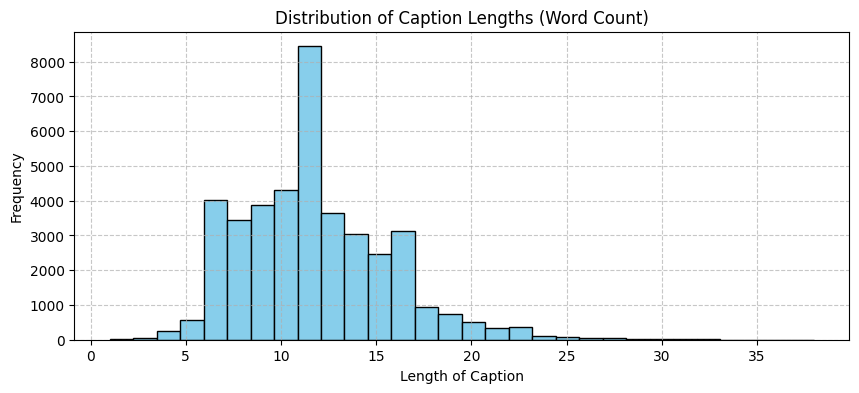

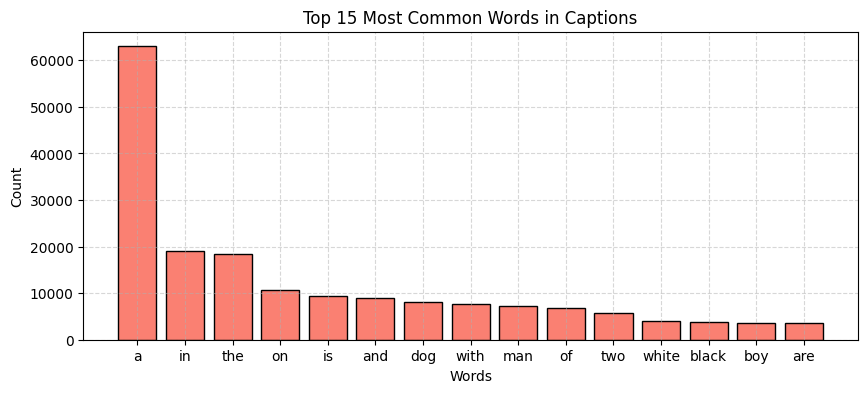

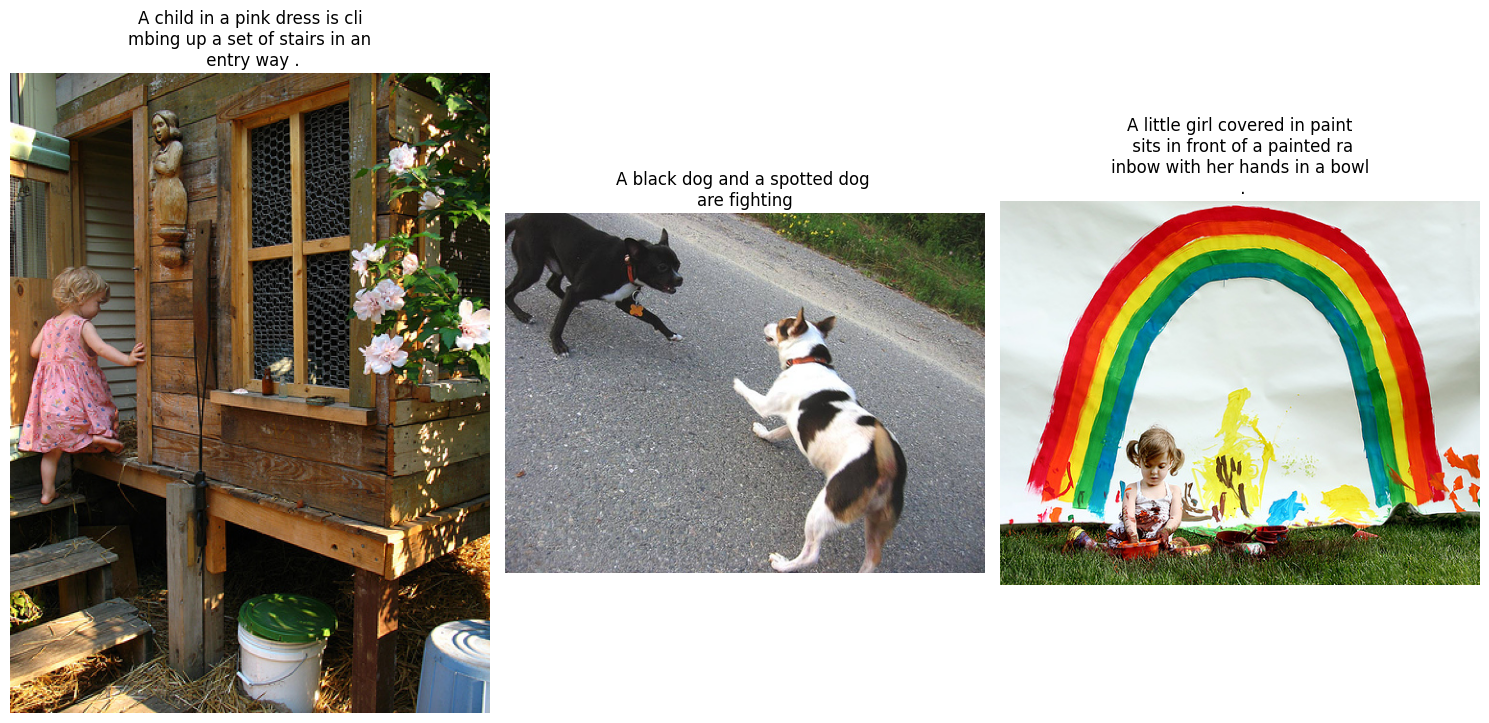

In [ ]:
import os
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
from PIL import Image

# 1. Load and parse the captions
token_path = './data/Flickr8k.token.txt'
img_dir = './data/Flicker8k_Dataset'

captions_dict = {}
all_captions = []

with open(token_path, 'r') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        img_id_with_cap_num, caption = line.split('\t')
        img_id = img_id_with_cap_num.split('#')[0]
        all_captions.append(caption)
        if img_id not in captions_dict:
            captions_dict[img_id] = []
        captions_dict[img_id].append(caption)

print(f"Total Images with Captions: {len(captions_dict)}")
print(f"Total Captions: {len(all_captions)}")

# 2. Caption Length Analysis
caption_lengths = [len(cap.split()) for cap in all_captions]
df_lengths = pd.DataFrame(caption_lengths, columns=['length'])
print("\n--- Caption Word Count Stats ---")
print(df_lengths.describe())

# Plotting distribution of caption lengths
plt.figure(figsize=(10, 4))
plt.hist(caption_lengths, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Caption Lengths (Word Count)')
plt.xlabel('Length of Caption')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 3. Vocabulary Frequency Analysis
words = []
for cap in all_captions:
    words.extend(cap.lower().replace('.', '').replace(',', '').split())

word_counts = Counter(words)
most_common = word_counts.most_common(15)

# Plotting most common words
plt.figure(figsize=(10, 4))
x_words = [item[0] for item in most_common]
y_counts = [item[1] for item in most_common]
plt.bar(x_words, y_counts, color='salmon', edgecolor='black')
plt.title('Top 15 Most Common Words in Captions')
plt.xlabel('Words')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 4. Display sample images with their captions
sample_img_ids = list(captions_dict.keys())[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

for i, img_id in enumerate(sample_img_ids):
    img_path = os.path.join(img_dir, img_id)
    if os.path.exists(img_path):
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].axis('off')
        # Use the first caption as title
        title_text = captions_dict[img_id][0]
        # Wrap title text if it is too long
        wrapped_title = '\n'.join([title_text[j:j+30] for j in range(0, len(title_text), 30)])
        axes[i].set_title(wrapped_title, fontsize=12)
    else:
        axes[i].text(0.5, 0.5, f"Image not found:\n{img_id}", ha='center', va='center')
        axes[i].axis('off')

plt.tight_layout()
plt.show()

### 🟠 Coordinated Multi-Modal Grid (Images & 5 Reference Captions)

### 🟠 Visualize Images with Reference Captions

Create a coordinated grid of Flickr8k images and their five reference captions to inspect the relationship between visual content and textual descriptions.

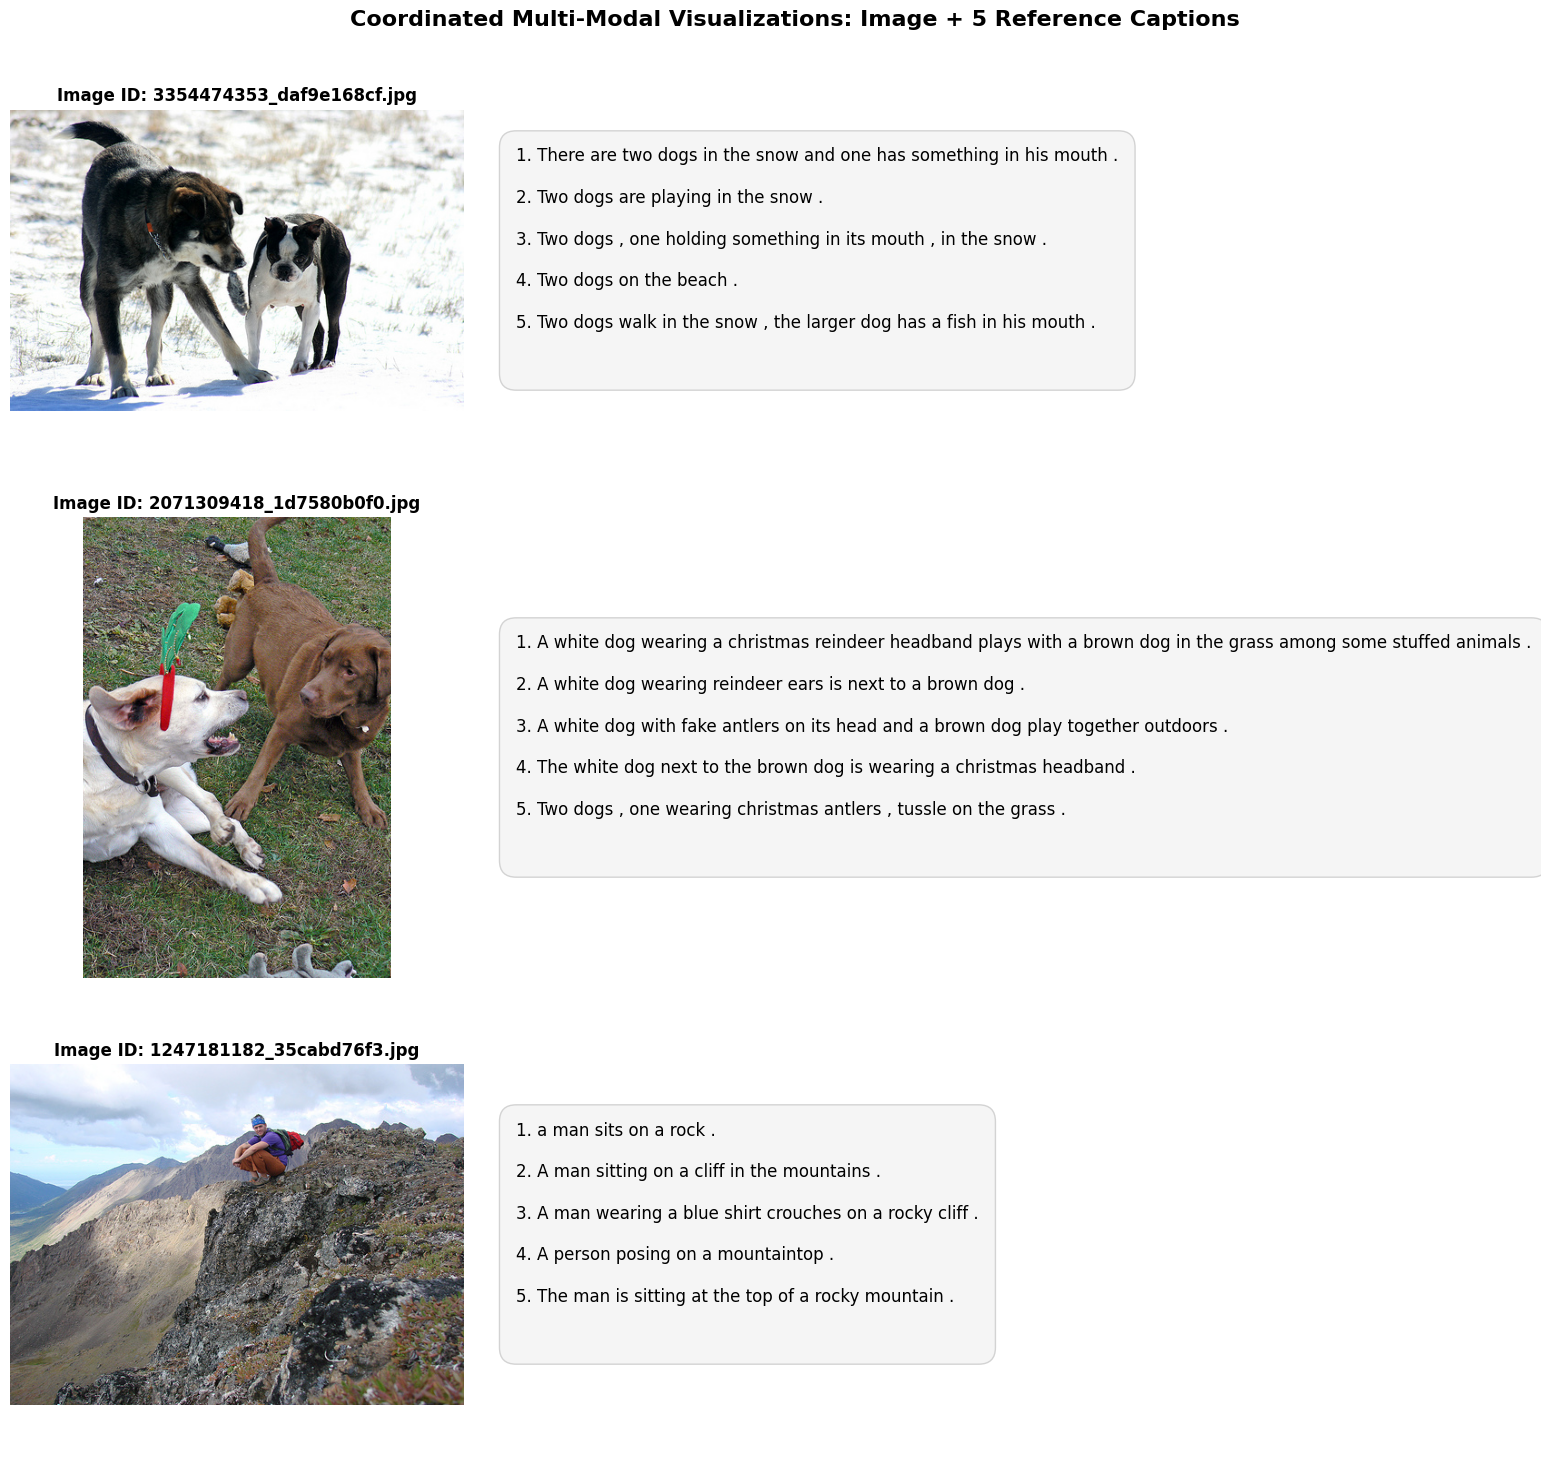

In [ ]:
import random
import matplotlib.pyplot as plt
import os
from PIL import Image

# Safely load captions from the dataset file directly to prevent NameError
token_path = './data/Flickr8k.token.txt'
img_dir = './data/Flicker8k_Dataset'

captions_dict = {}
with open(token_path, 'r') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        img_id_with_cap_num, caption = line.split('\t')
        img_id = img_id_with_cap_num.split('#')[0]
        if img_id not in captions_dict:
            captions_dict[img_id] = []
        captions_dict[img_id].append(caption)

# Selecting 3 random images
random.seed(42)
sample_ids = random.sample(list(captions_dict.keys()), 3)

# Create a multi-modal grid
fig, axes = plt.subplots(3, 2, figsize=(16, 15), gridspec_kw={'width_ratios': [1.2, 2.0]})

for i, img_id in enumerate(sample_ids):
    # 1. Plot the Image on the Left column
    img_path = os.path.join(img_dir, img_id)
    if os.path.exists(img_path):
        img = Image.open(img_path)
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Image ID: {img_id}", fontsize=12, fontweight='bold')
    else:
        axes[i, 0].text(0.5, 0.5, "Image Missing", ha='center', va='center')
    axes[i, 0].axis('off')

    # 2. Render all 5 Reference Captions on the Right column
    axes[i, 1].axis('off')
    caption_text = ""
    for j, cap in enumerate(captions_dict[img_id], 1):
        caption_text += f"{j}. {cap.strip()}\n\n"

    # Add a text box containing the captions
    axes[i, 1].text(0.05, 0.5, caption_text, fontsize=12, va='center', ha='left',
                     bbox=dict(boxstyle='round,pad=1', facecolor='whitesmoke', edgecolor='lightgrey'))

plt.suptitle("Coordinated Multi-Modal Visualizations: Image + 5 Reference Captions", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### 🟠Bi-grams and Caption Density Analysis

### 🟠 Bigram and Caption-Density Analysis

Analyze common consecutive word pairs (bigrams) and the distribution of caption content to identify frequent linguistic patterns in the dataset.

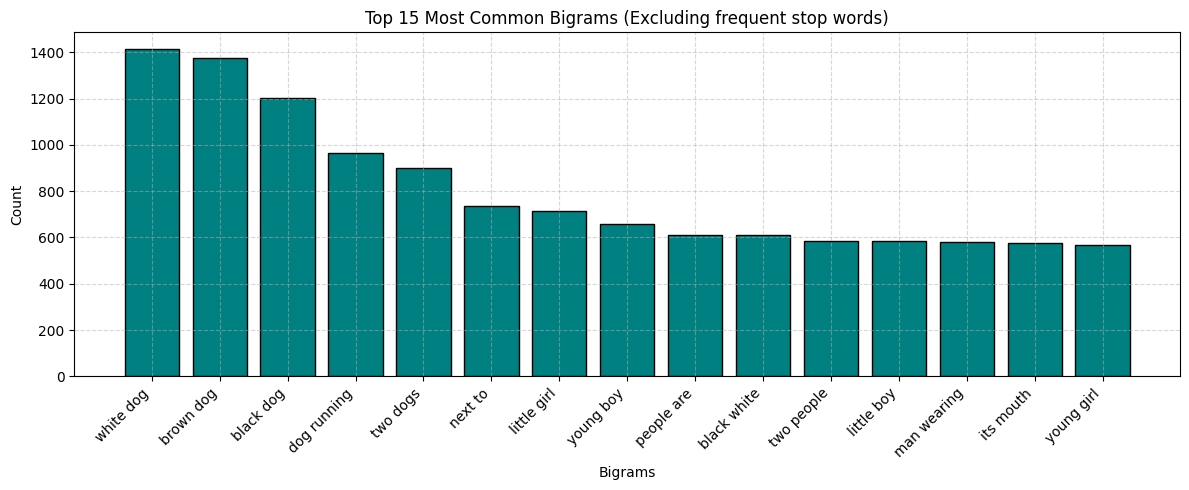

In [ ]:
# 1. Bigram Analysis (Common consecutive word pairs)
from nltk.util import ngrams

# Tokenize words cleanly
clean_words = [w for w in words if w not in ['.', ',', 'a', 'in', 'the', 'on', 'is', 'and', 'with', 'of']]
bigrams_list = list(ngrams(clean_words, 2))
bigram_counts = Counter(bigrams_list)
common_bigrams = bigram_counts.most_common(15)

# Visualize Bigrams
plt.figure(figsize=(12, 5))
bigram_labels = [f"{w1} {w2}" for (w1, w2), _ in common_bigrams]
bigram_values = [count for _, count in common_bigrams]

plt.bar(bigram_labels, bigram_values, color='teal', edgecolor='black')
plt.title('Top 15 Most Common Bigrams (Excluding frequent stop words)')
plt.xlabel('Bigrams')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 🟠 Vocabulary "Long Tail" and Cutoff Analysis
To build a robust and computationally efficient model, we need to analyze rare words (the long tail of the vocabulary). This snippet calculates how much of the vocabulary consists of rare words and visualizes how a threshold cutoff affects both the vocabulary size and the percentage of out-of-vocabulary (OOV or `<unk>`) tokens.

### 🟠 Vocabulary Long-Tail and Cutoff Analysis

Examine word-frequency distribution to identify rare words and evaluate how vocabulary cutoffs could affect the captioning task.

Total unique words: 8911
Total tokens in corpus: 436893

Threshold >=  1: Retained Vocab Size =  8911 (100.0%) | OOV/Unk % = 0.00%
Threshold >=  2: Retained Vocab Size =  5235 ( 58.7%) | OOV/Unk % = 0.84%
Threshold >=  3: Retained Vocab Size =  4104 ( 46.1%) | OOV/Unk % = 1.36%
Threshold >=  5: Retained Vocab Size =  2999 ( 33.7%) | OOV/Unk % = 2.22%
Threshold >= 10: Retained Vocab Size =  1961 ( 22.0%) | OOV/Unk % = 3.78%
Threshold >= 20: Retained Vocab Size =  1292 ( 14.5%) | OOV/Unk % = 5.89%


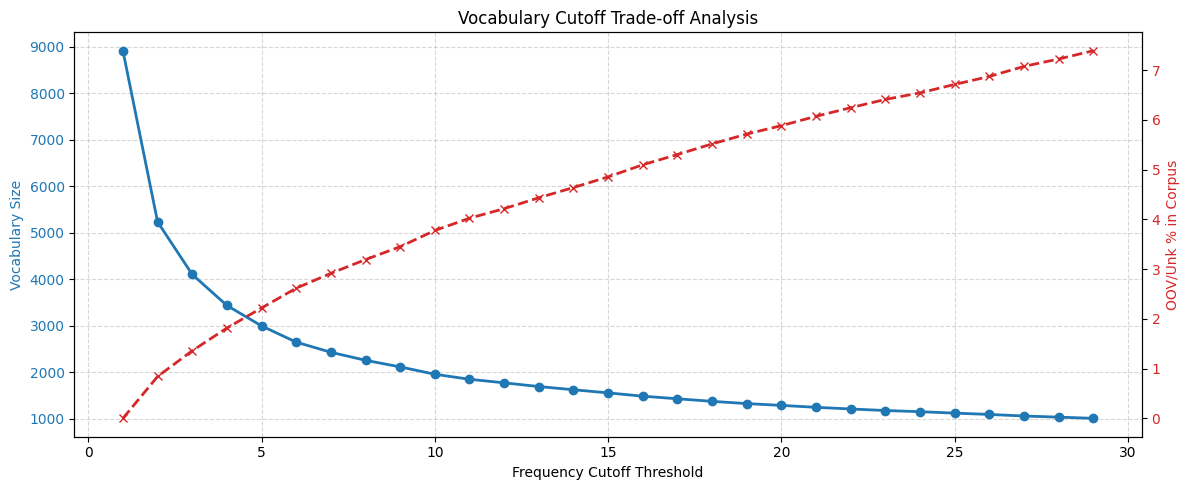

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Safely load captions from the dataset file directly to prevent NameError
token_path = './data/Flickr8k.token.txt'
all_captions = []
with open(token_path, 'r') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        img_id_with_cap_num, caption = line.split('\t')
        all_captions.append(caption)

# Count all word frequencies in the dataset captions
all_words = []
for cap in all_captions:
    all_words.extend(cap.lower().replace('.', '').replace(',', '').split())

word_counts = Counter(all_words)
total_unique_words = len(word_counts)
total_token_count = len(all_words)

# Calculate statistics for rare words
print(f"Total unique words: {total_unique_words}")
print(f"Total tokens in corpus: {total_token_count}\n")

thresholds = [1, 2, 3, 5, 10, 20]
for t in thresholds:
    retained_vocab = [word for word, count in word_counts.items() if count >= t]
    retained_tokens_count = sum(word_counts[word] for word in retained_vocab)
    oov_percentage = (1 - (retained_tokens_count / total_token_count)) * 100
    print(f"Threshold >= {t:2d}: Retained Vocab Size = {len(retained_vocab):5d} ({len(retained_vocab)/total_unique_words*100:5.1f}%) | OOV/Unk % = {oov_percentage:.2f}%")

# Plot the cumulative coverage and vocabulary size reduction
thresholds_plot = list(range(1, 30))
vocab_sizes = []
oov_percentages = []

for t in thresholds_plot:
    retained_vocab = [word for word, count in word_counts.items() if count >= t]
    retained_tokens_count = sum(word_counts[word] for word in retained_vocab)
    vocab_sizes.append(len(retained_vocab))
    oov_percentages.append((1 - (retained_tokens_count / total_token_count)) * 100)

fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Frequency Cutoff Threshold')
ax1.set_ylabel('Vocabulary Size', color=color)
ax1.plot(thresholds_plot, vocab_sizes, color=color, marker='o', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('OOV/Unk % in Corpus', color=color)
ax2.plot(thresholds_plot, oov_percentages, color=color, marker='x', linestyle='--', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Vocabulary Cutoff Trade-off Analysis')
fig.tight_layout()
plt.show()

### 🟠 Visual Subjects (Nouns) & Actions (Verbs) Semantic Analysis

### 🟠 Semantic Analysis of Subjects and Actions

Use part-of-speech information to inspect common nouns and verbs in the captions, providing a simple view of the visual subjects and actions described.

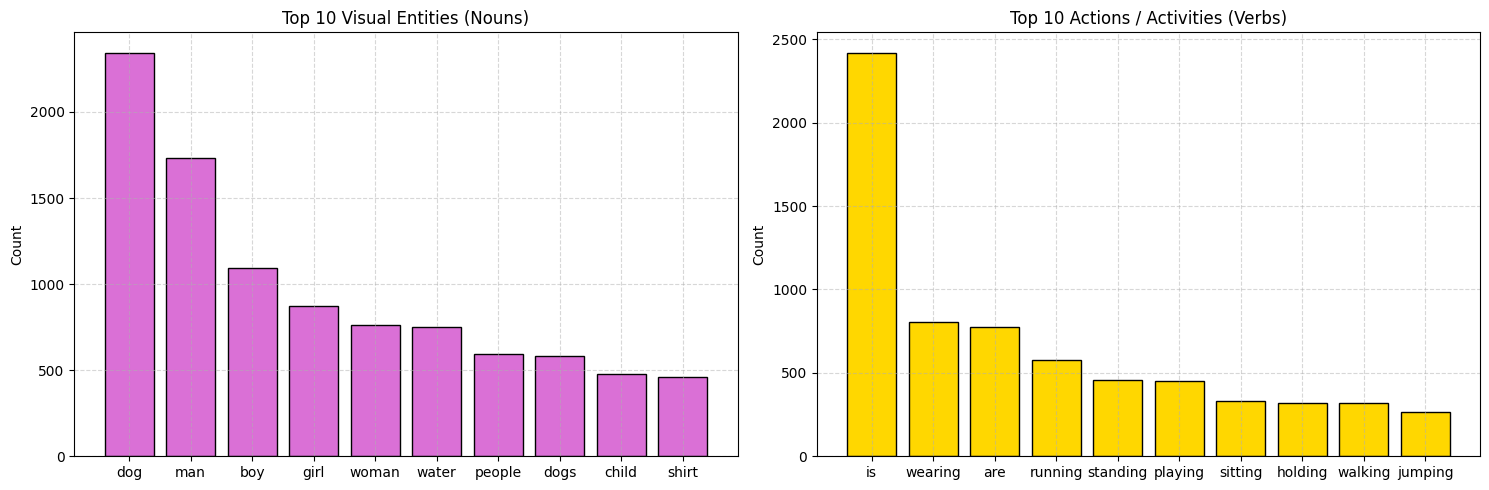

In [ ]:
import nltk
# Download the updated English-specific POS tagger model to fix the LookupError
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)

# POS Tagging the vocabulary
# We take a sample of captions to speed up computation
sample_caps = all_captions[:10000]
tagged_words = []

for cap in sample_caps:
    tokenized = cap.lower().replace('.', '').replace(',', '').split()
    tagged_words.extend(nltk.pos_tag(tokenized))

# Extract Nouns and Verbs
nouns = [word for word, tag in tagged_words if tag.startswith('NN')]
verbs = [word for word, tag in tagged_words if tag.startswith('VB')]

noun_counts = Counter(nouns).most_common(10)
verb_counts = Counter(verbs).most_common(10)

# Plot the results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Nouns (Objects/Subjects)
axes[0].bar([w for w, c in noun_counts], [c for w, c in noun_counts], color='orchid', edgecolor='black')
axes[0].set_title('Top 10 Visual Entities (Nouns)')
axes[0].set_ylabel('Count')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Verbs (Actions)
axes[1].bar([w for w, c in verb_counts], [c for w, c in verb_counts], color='gold', edgecolor='black')
axes[1].set_title('Top 10 Actions / Activities (Verbs)')
axes[1].set_ylabel('Count')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 🟠 Aspect Ratio and Resolution Analysis

### 🟠 Image Aspect Ratio and Resolution Analysis

Inspect the original Flickr8k image dimensions and aspect ratios to understand the variability that the image preprocessing pipeline must handle.

--- Image Shape Distribution ---
shape_type
Landscape (Horizontal)    679
Portrait (Vertical)       285
Square                     36
Name: count, dtype: int64

--- Aspect Ratio Stats ---
count    1000.000000
mean        1.223640
std         0.379351
min         0.400000
25%         0.800000
50%         1.333333
75%         1.501502
max         3.311258
Name: aspect_ratio, dtype: float64


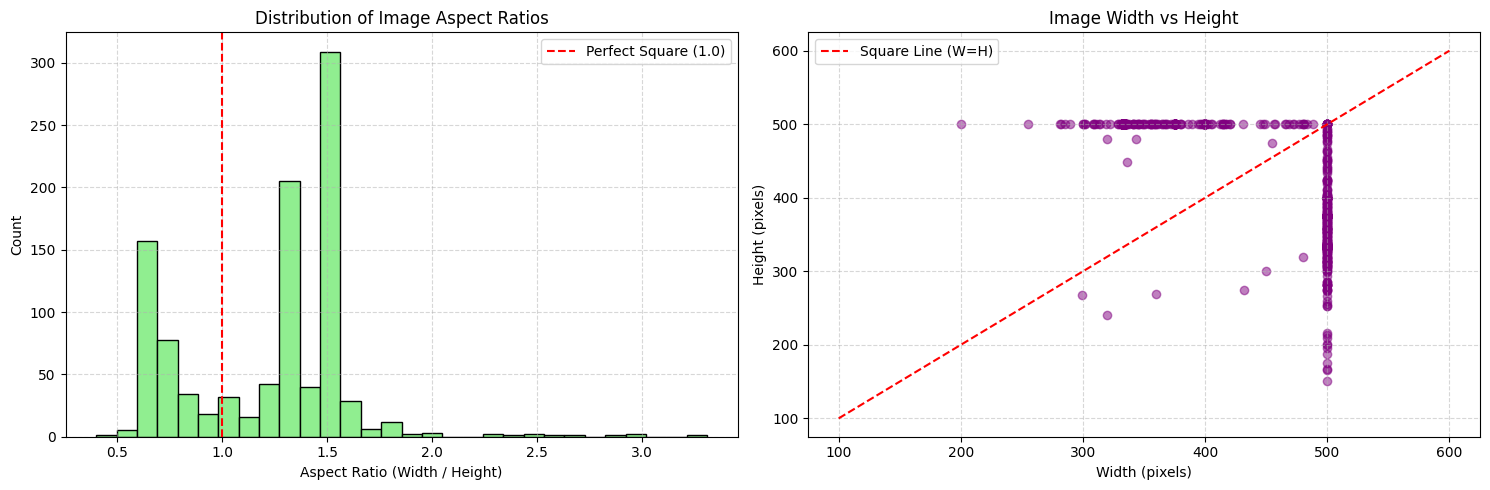

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Path to the image directory
img_dir = './data/Flicker8k_Dataset'
img_names = os.listdir(img_dir)

# 1. Collect dimensions
sizes = []
for img_name in img_names[:1000]:  # Sampling 1000 images for speed
    img_path = os.path.join(img_dir, img_name)
    try:
        with Image.open(img_path) as img:
            w, h = img.size
            sizes.append({'width': w, 'height': h, 'aspect_ratio': w / h})
    except Exception as e:
        continue

df_sizes = pd.DataFrame(sizes)

# Classify shapes
def classify_shape(row):
    ratio = row['aspect_ratio']
    if abs(ratio - 1.0) < 0.05:
        return 'Square'
    elif ratio > 1.0:
        return 'Landscape (Horizontal)'
    else:
        return 'Portrait (Vertical)'

df_sizes['shape_type'] = df_sizes.apply(classify_shape, axis=1)

# Print Summary statistics
print("--- Image Shape Distribution ---")
print(df_sizes['shape_type'].value_counts())
print("\n--- Aspect Ratio Stats ---")
print(df_sizes['aspect_ratio'].describe())

# 2. Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Aspect Ratio Histogram
axes[0].hist(df_sizes['aspect_ratio'], bins=30, color='lightgreen', edgecolor='black')
axes[0].axvline(1.0, color='red', linestyle='--', label='Perfect Square (1.0)')
axes[0].set_title('Distribution of Image Aspect Ratios')
axes[0].set_xlabel('Aspect Ratio (Width / Height)')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Width vs Height scatter
axes[1].scatter(df_sizes['width'], df_sizes['height'], alpha=0.5, color='purple')
axes[1].plot([100, 600], [100, 600], color='red', linestyle='--', label='Square Line (W=H)')
axes[1].set_title('Image Width vs Height')
axes[1].set_xlabel('Width (pixels)')
axes[1].set_ylabel('Height (pixels)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 🟠 visualizing the difference between simple **forced resizing** (which distorts the subjects by squeezing or stretching them) and **center cropping** (which preserves the aspect ratio at the expense of discarding the boundaries)

### 🟠 Compare Resize Distortion with Aspect-Ratio-Preserving Cropping

Visualize the difference between direct resizing to a fixed shape and center cropping, highlighting the effect of preprocessing on image geometry.

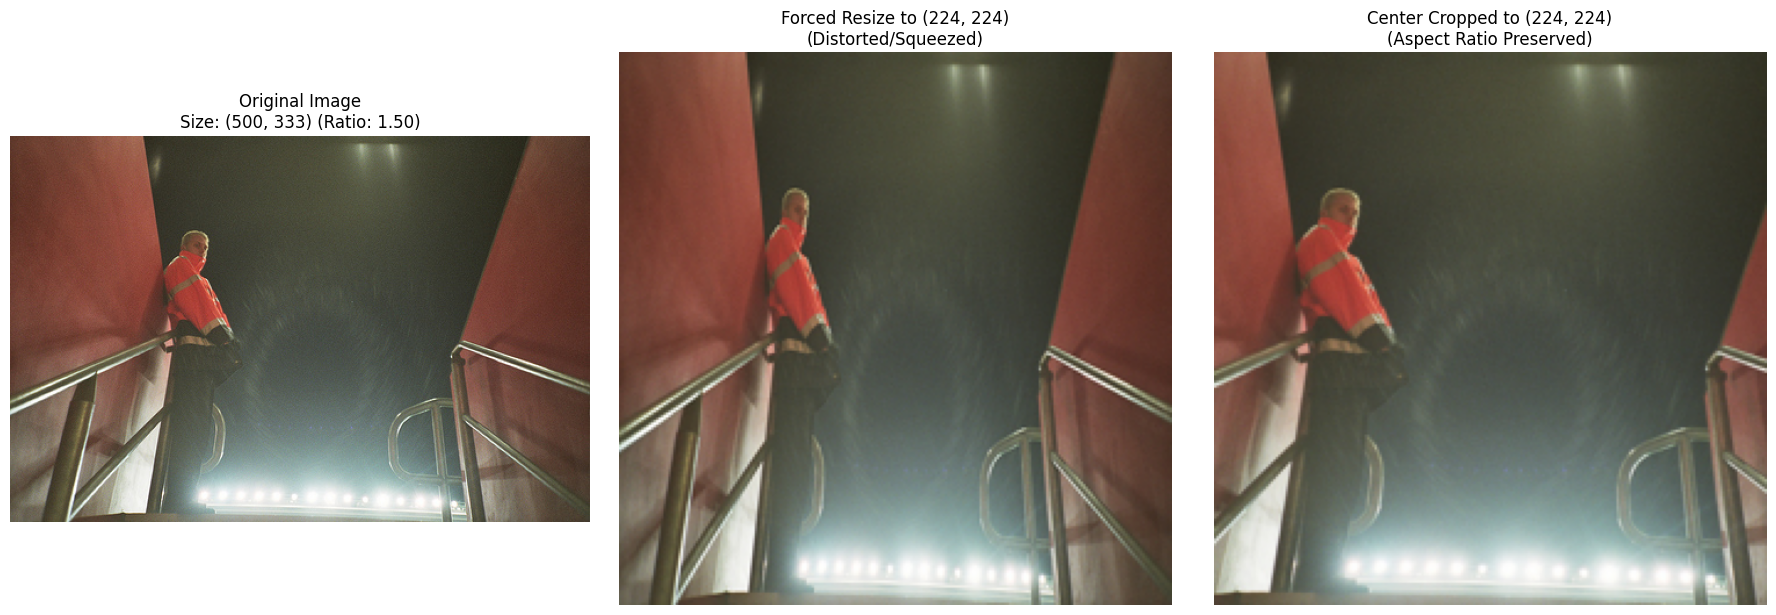

In [ ]:
# 3. Visualizing Resize Distortion vs Aspect-Ratio Preserving Crop
sample_img_path = os.path.join(img_dir, img_names[0])
original_img = Image.open(sample_img_path)

target_size = (224, 224)

# Standard forced resize (causes distortion if not square)
distorted_resized = original_img.resize(target_size)

# Center Crop (preserves aspect ratio)
from torchvision.transforms import functional as F_tf
# Convert to tensor to easily use torchvision functional helpers
temp_tensor = torchvision.transforms.ToTensor()(original_img)
# Resize shorter side to 224, then crop center to 224x224
shorter_side = min(original_img.size)
scale_factor = 224 / shorter_side
new_size = (int(original_img.size[1] * scale_factor), int(original_img.size[0] * scale_factor))
cropped_resized_tensor = torchvision.transforms.Compose([
    torchvision.transforms.Resize(224),
    torchvision.transforms.CenterCrop(224)
])(original_img)

# Plot Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(original_img)
axes[0].set_title(f"Original Image\nSize: {original_img.size} (Ratio: {original_img.size[0]/original_img.size[1]:.2f})")
axes[0].axis('off')

axes[1].imshow(distorted_resized)
axes[1].set_title(f"Forced Resize to {target_size}\n(Distorted/Squeezed)")
axes[1].axis('off')

axes[2].imshow(cropped_resized_tensor)
axes[2].set_title(f"Center Cropped to {target_size}\n(Aspect Ratio Preserved)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 🟠 Custom dataset

### 🟠 Review Alternative Flickr8k Dataset Interfaces

Show earlier dataset-interface experiments kept as reference code before the custom `Flickr8k` dataset implementation is used.

In [ ]:
# dataset = torchvision.datasets.Flickr8k('./data/Flicker8k_Dataset',
#                                         './data/8k-pictures.html')
# dataset.annotations
# dataset.ids

In [ ]:
# dataset = torchvision.datasets.Flickr30k('./data/Flicker8k_Dataset',
#                                          './data/Flickr8k.token.txt')
# dataset.annotations

### 🟠 Define the Custom Flickr8k Dataset

Implement a custom PyTorch dataset that reads image files, split definitions, and captions, and returns either training samples or raw images with captions for evaluation.

In [ ]:
class Flickr8k(VisionDataset):
    """
    Args:
        root (string): Root directory where images are downloaded to.
        ann_file (string): Path to annotation file.
        transform (callable, optional): A function/transform that takes in a PIL image
            and returns a transformed version. E.g, ``transforms.PILToTensor``
        target_transform (callable, optional): A function/transform that takes in the
            target and transforms it.
    """

    def __init__(
        self,
        root: str,
        ann_file: str,
        split_file: str,
        train: bool,
        transform: Optional[Callable] = None,
        target_transform: Optional[Callable] = None,
    ) -> None:
        super().__init__(root, transform=transform, target_transform=target_transform)
        self.ann_file = os.path.expanduser(ann_file)
        self.train = train

        # Read {train/dev/test} files
        with open(split_file) as f:
            self.split_samples = f.read().strip().split("\n")

        # Read annotations and store in a dict
        self.ids, self.captions = [], []
        with open(self.ann_file) as fh:
            for line in fh:
                img_id, caption = line.strip().split("\t")
                if img_id[:-2] in self.split_samples:
                    self.ids.append(img_id[:-2])
                    self.captions.append(caption)

    def __getitem__(self, index: int) -> Tuple[Any, Any]:
        """
        Args:
            index (int): Index

        Returns:
            tuple: Tuple (image, target). target is a list of captions for the image.
        """
        img_id = self.ids[index]

        # Image
        filename = os.path.join(self.root, img_id)
        img_raw = Image.open(filename).convert("RGB")
        if self.transform is not None:
            img = self.transform(img_raw)

        # Captions
        caption = self.captions[index]
        if self.target_transform is not None:
            target = self.target_transform(caption)

        if self.train:
            return img, target
        else:
          return img, img_raw, caption

    def __len__(self) -> int:
        return len(self.ids)

### 🟠 Initialize the Training Dataset

Create the initial Flickr8k training dataset using the custom dataset class and inspect the resulting dataset object.

In [ ]:
dataset = Flickr8k('./data/Flicker8k_Dataset',
                    './data/Flickr8k.token.txt',
                   './data/Flickr_8k.trainImages.txt',
                   True)
dataset

Dataset Flickr8k
    Number of datapoints: 30000
    Root location: ./data/Flicker8k_Dataset

### 🟠 Inspect the Training Split

Check the number of image identifiers included in the selected training split.

In [ ]:
len(dataset.split_samples)

6000

### 🟠 Build the Caption Vocabulary

Define a caption transformation that tokenizes captions, constructs a vocabulary with special tokens, and converts each caption into integer token IDs.

In [ ]:
class CaptionTransform:

    def __init__(self, caption_file):
        captions = self._load_captions(caption_file)

        self.tokenizer = get_tokenizer('basic_english')
        self.vocab = build_vocab_from_iterator(map(self.tokenizer, captions),
                                               specials=['<pad>', '<unk>', '<sos>', '<eos>'])
        self.vocab.set_default_index(self.vocab['<unk>'])

        torch.save(self.vocab, 'vocab.pt')

    def __call__(self, caption):
        indices = self.vocab(self.tokenizer(caption))
        indices = self.vocab(['<sos>']) + indices + self.vocab(['<eos>'])
        target = torch.LongTensor(indices)
        return target

    def __repr__(self):
        return f"""CaptionTransform([
          _load_captions(),
          toknizer('basic_english'),
          vocab(vocab_size={len(self.vocab)})
          ])
          """

    def _load_captions(self, caption_file):
        captions = []
        with open(caption_file) as f:
            for line in f:
                _, caption = line.strip().split("\t")
                captions.append(caption)
        return captions

### 🟠 Create the Caption Vocabulary with the Installed `torchtext` API

Redefine the caption transformation using the legacy `torchtext` vocabulary API required by the installed environment, then create and test the vocabulary.

In [ ]:
from torchtext.data.utils import get_tokenizer
from collections import Counter
from torchtext.vocab import Vocab
import torch

# Redefining CaptionTransform to be compatible with torchtext 0.6.0
class CaptionTransform:
    def __init__(self, caption_file):
        captions = self._load_captions(caption_file)
        self.tokenizer = get_tokenizer('basic_english')

        # Manually count tokens and build legacy Vocab
        counter = Counter()
        for caption in captions:
            counter.update(self.tokenizer(caption))

        self.vocab = Vocab(counter, specials=['<pad>', '<unk>', '<sos>', '<eos>'])
        # set default index for unknown tokens
        self.vocab.default_index = self.vocab['<unk>']
        torch.save(self.vocab, 'vocab.pt')

    def __call__(self, caption):
        indices = [self.vocab[token] for token in self.tokenizer(caption)]
        indices = [self.vocab['<sos>']] + indices + [self.vocab['<eos>']]
        target = torch.LongTensor(indices)
        return target

    def __repr__(self):
        return f"""CaptionTransform([
          _load_captions(),
          toknizer('basic_english'),
          vocab(vocab_size={len(self.vocab)})
          ])
          """

    def _load_captions(self, caption_file):
        captions = []
        with open(caption_file) as f:
            for line in f:
                _, caption = line.strip().split("\t")
                captions.append(caption)
        return captions

caption_transform = CaptionTransform('./data/Flickr8k.token.txt')
print(caption_transform)
print(len(caption_transform.vocab))
caption_transform('how are you')

CaptionTransform([
          _load_captions(),
          toknizer('basic_english'),
          vocab(vocab_size=8915)
          ])
          
8915


tensor([   2, 1352,   19, 1382,    3])

### 🟠 Define the Basic Image Transform

Create the initial image transformation that converts PIL images into PyTorch tensors.

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])

### 🟠 Create the Transformed Flickr8k Dataset

Connect the image transformation and caption-tokenization transformation to the custom dataset so each sample is returned in model-ready form.

In [ ]:
dataset = Flickr8k('./data/Flicker8k_Dataset',
                   './data/Flickr8k.token.txt',
                   './data/Flickr_8k.trainImages.txt',
                   train=True,
                   transform=transform,
                   target_transform=caption_transform)
dataset

Dataset Flickr8k
    Number of datapoints: 30000
    Root location: ./data/Flicker8k_Dataset
    StandardTransform
Transform: Compose(
               ToTensor()
           )
Target transform: CaptionTransform([
                            _load_captions(),
                            toknizer('basic_english'),
                            vocab(vocab_size=8915)
                            ])
                            

### 🟠 Inspect a Tokenized Dataset Sample

Retrieve one training example to verify the encoded caption and transformed image produced by the dataset pipeline.

In [ ]:
img, caption = dataset[50]
print(caption)
img

tensor([ 2,  4, 30, 10, 16, 11,  9, 35, 36,  7, 47,  5,  3])


tensor([[[0.0941, 0.1059, 0.1255,  ..., 0.2392, 0.2275, 0.2235],
         [0.1098, 0.1176, 0.1137,  ..., 0.2471, 0.2431, 0.2431],
         [0.1020, 0.1255, 0.1255,  ..., 0.2745, 0.2667, 0.2667],
         ...,
         [0.8706, 0.8706, 0.8667,  ..., 0.8824, 0.8745, 0.8784],
         [0.8627, 0.8627, 0.8627,  ..., 0.8784, 0.8667, 0.8627],
         [0.8667, 0.8667, 0.8667,  ..., 0.8706, 0.8510, 0.8471]],

        [[0.1098, 0.1098, 0.1294,  ..., 0.1686, 0.1569, 0.1529],
         [0.1176, 0.1255, 0.1137,  ..., 0.1725, 0.1686, 0.1686],
         [0.1020, 0.1255, 0.1255,  ..., 0.1882, 0.1804, 0.1804],
         ...,
         [0.8784, 0.8784, 0.8745,  ..., 0.8784, 0.8745, 0.8784],
         [0.8706, 0.8706, 0.8706,  ..., 0.8745, 0.8667, 0.8627],
         [0.8667, 0.8667, 0.8667,  ..., 0.8667, 0.8510, 0.8471]],

        [[0.0549, 0.0784, 0.1059,  ..., 0.1216, 0.1098, 0.0980],
         [0.0667, 0.0824, 0.0824,  ..., 0.1176, 0.1137, 0.1137],
         [0.0627, 0.0784, 0.0784,  ..., 0.1333, 0.1255, 0.

## 🟠 Prepare the Transformer-Based Data Pipeline

Define the train, validation, and test splits, configure ViT-compatible image preprocessing, initialize the GPT-2 tokenizer, and create the final dataset objects used by the model.

In [ ]:
root = './data/Flicker8k_Dataset'
ann_file = './data/Flickr8k.token.txt'

def split_file(split):
    if split == 'train':
        return './data/Flickr_8k.trainImages.txt'
    elif split == 'dev':
        return './data/Flickr_8k.devImages.txt'
    elif split == 'test':
        return './data/Flickr_8k.testImages.txt'
    else:
        raise ValueError(f"Unknown split: {split}")

# Initialize ViT Image Processor
image_processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224-in21k')

# Transformers compatible data transforms using standard torchvision pipelines
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=image_processor.image_mean, std=image_processor.image_std)
])

# Load Legacy GPT2 Tokenizer and Build Caption Map
tok_path = './data/Flickr8k.token.txt'
tokenizer = GPT2TokenizerFast.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

class TransformerCaptionTransform:
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer
    def __call__(self, caption):
        tokens = self.tokenizer(caption, truncation=True, max_length=20, return_tensors='pt')
        return tokens['input_ids'].squeeze(0)

caption_transform = TransformerCaptionTransform(tokenizer)

train_set = Flickr8k(root, ann_file, split_file('train'), True, train_transform, caption_transform)
valid_set = Flickr8k(root, ann_file, split_file('dev'), True, eval_transform, caption_transform)
test_set = Flickr8k(root, ann_file, split_file('test'), False, eval_transform, caption_transform)

print(f"Train size: {len(train_set)}, Validation size: {len(valid_set)}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Train size: 30000, Validation size: 5000


## 🟠 Define a dataloader

### 🟠 Define the Batch Collation Function

Combine variable-length caption sequences into padded batches while handling the different sample structure used for training and test-time evaluation.

In [ ]:
def collate_fn(batch):
    if len(batch[0]) == 2:
        x_batch, y_batch = zip(*batch)
        x_batch = torch.stack(x_batch)
        y_batch = pad_sequence(y_batch, batch_first=True, padding_value=tokenizer.pad_token_id)
        return x_batch, y_batch
    else:
        x_batch, x_raw, captions = zip(*batch)
        x_batch = torch.stack(x_batch)
        return x_batch, x_raw, captions

### 🟠 Create Train, Validation, and Test DataLoaders

Construct the DataLoaders used to feed batched image-caption data into training, validation, and testing.

In [ ]:
import torch
torch.cuda.empty_cache()

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
valid_loader = DataLoader(valid_set, batch_size=batch_size*2, collate_fn=collate_fn)
test_loader = DataLoader(test_set, batch_size=batch_size*2, collate_fn=collate_fn)

### 🟠 Verify Batch Shapes

Retrieve one training batch and inspect the image and caption tensor shapes to confirm that batching and padding work as expected.

In [ ]:
x_batch, y_batch = next(iter(train_loader))
x_batch.shape, y_batch.shape

(torch.Size([16, 3, 224, 224]), torch.Size([16, 15]))

# 🔴 **Model**

## 🟠 Define the ViT–GPT-2 Image Captioning Model

Build the captioning model by using a pretrained Vision Transformer as the image encoder and GPT-2 as the autoregressive text decoder, with a projection layer connecting their hidden representations.

In [ ]:
class ViTGPT2Captioner(nn.Module):
    def __init__(self, encoder_name='google/vit-base-patch16-224-in21k', decoder_name='gpt2'):
        super().__init__()
        # 1. Image Processor and Feature Extractor
        self.feature_extractor = ViTImageProcessor.from_pretrained(encoder_name)
        self.encoder = ViTModel.from_pretrained(encoder_name)
        self.encoder.requires_grad_(False) # Freeze ViT weights

        # 2. Tokenizer and Decoder
        self.tokenizer = GPT2TokenizerFast.from_pretrained(decoder_name)
        self.tokenizer.pad_token = self.tokenizer.eos_token
        self.decoder = GPT2LMHeadModel.from_pretrained(decoder_name)

        # Projection layer to map ViT hidden state (768) to GPT-2 embedding size (768)
        self.project_features = nn.Linear(self.encoder.config.hidden_size, self.decoder.config.n_embd)

    def forward(self, pixel_values, input_ids, labels=None):
        # Extract image features: [Batch, Sequence_Len (197), Hidden_Size]
        encoder_outputs = self.encoder(pixel_values=pixel_values)
        image_features = encoder_outputs.last_hidden_state
        projected_features = self.project_features(image_features)
        num_image_tokens = projected_features.size(1)

        # Prepare inputs to GPT-2
        word_embeddings = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat((projected_features, word_embeddings), dim=1)

        outputs = self.decoder(inputs_embeds=inputs_embeds)
        logits = outputs.logits

        # Slice logits to only keep the text sequence predictions (ignoring image tokens)
        text_logits = logits[:, num_image_tokens:, :]

        loss = None
        if labels is not None:
            # Shift logits and labels for autoregressive training
            shift_logits = text_logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            # Flatten tensors for CrossEntropyLoss
            loss_fct = nn.CrossEntropyLoss(ignore_index=self.tokenizer.pad_token_id)
            loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))

        # Return a namespace class compatible with Hugging Face outputs
        from transformers.modeling_outputs import CausalLMOutputWithCrossAttentions
        return CausalLMOutputWithCrossAttentions(loss=loss, logits=logits)

    def generate(self, pixel_values, max_length=20, device='cuda'):
        self.eval()
        with torch.no_grad():
            encoder_outputs = self.encoder(pixel_values=pixel_values.to(device))
            image_features = encoder_outputs.last_hidden_state
            projected_features = self.project_features(image_features)

            generated = torch.tensor([[self.tokenizer.bos_token_id]]).to(device)

            for _ in range(max_length):
                word_embeddings = self.decoder.transformer.wte(generated)
                inputs_embeds = torch.cat((projected_features, word_embeddings), dim=1)
                outputs = self.decoder(inputs_embeds=inputs_embeds)

                next_token_logits = outputs.logits[:, -1, :]
                next_token = torch.argmax(next_token_logits, dim=-1, keepdim=True)

                generated = torch.cat((generated, next_token), dim=1)
                if next_token.item() == self.tokenizer.eos_token_id:
                    break

            caption = self.tokenizer.decode(generated[0], skip_special_tokens=True)
            return caption

# 🔴 **Config**

### 🟠 Select the Compute Device

Choose CUDA when a GPU is available; otherwise fall back to the CPU.

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

### 🟠 Define the Training Loss

Configure token-level cross-entropy loss while ignoring padded caption tokens so padding does not contribute to the training objective.

In [ ]:
# Initialize CrossEntropyLoss ignoring the GPT-2 padding token
loss_fn = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_token_id)

metric = None

### 🟠 Configure Weights & Biases Authentication

If experiment tracking is enabled, load the API key from the local key file and log in to Weights & Biases.

In [ ]:
if wandb_enable:
    key_file = '/content/key'

    if os.path.exists(key_file):
        with open(key_file) as f:
            key = f.readline().strip()
        wandb.login(key=key)
    else:
        print("Key file does not exist. Please create the key file with your wandb API key.")

# 🔴 **Train ➰**

## 🟠 Define the Training Procedure

Implement one training epoch: run the model in training mode, compute the captioning loss, backpropagate gradients, clip gradient norms, and update the model parameters.

In [ ]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, metric, epoch=None):
    model.train()
    loss_train = AverageMeter()

    with tqdm.tqdm(train_loader, unit='batch') as tepoch:
        for inputs, targets in tepoch:
            if epoch:
                tepoch.set_description(f'Epoch {epoch}')

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs, targets, labels=targets)
            loss = outputs.loss

            loss.backward()
            nn.utils.clip_grad.clip_grad_norm_(model.parameters(), max_norm=0.25)
            optimizer.step()

            loss_train.update(loss.item(), n=len(targets))
            tepoch.set_postfix(loss=loss_train.avg)

    return model, loss_train.avg, None

# 🔴 **Evaluation**

## 🟠 Define the Evaluation Procedure

Implement validation/evaluation without gradient computation and accumulate the average captioning loss across the evaluation DataLoader.

In [ ]:
def evaluate(model, test_loader, loss_fn, metric):
    model.eval()
    loss_eval = AverageMeter()

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs, targets, labels=targets)
            loss = outputs.loss
            loss_eval.update(loss.item(), n=len(targets))

    return loss_eval.avg, None

# 🔴 **Training Process 〽️**

## 🟠 Finding Hyper-parameters

### 🟡 **Step 1:** Calculate the loss for an untrained model using a few batches.


### 🟡 Step 1: Measure Initial Loss

Evaluate the untrained captioning model on a small batch to establish a baseline cross-entropy loss before fine-tuning.

In [ ]:
model = ViTGPT2Captioner().to(device)
inputs, targets = next(iter(train_loader))
inputs = inputs.to(device)
targets = targets.to(device)

with torch.no_grad():
    outputs = model(inputs, targets, labels=targets)
    loss = outputs.loss

print(f"Initial pre-trained model cross entropy loss: {loss.item():.4f}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Initial pre-trained model cross entropy loss: 5.9574


### 🟡 **Step 2:** Try to train and overfit the model on a small subset of the dataset.

### 🟡 Step 2: Initialize the Optimizer for the Overfitting Test

Create an SGD optimizer for the model as preparation for testing whether the network can overfit a small subset of the training data.

In [ ]:
model = ViTGPT2Captioner().to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

### 🟡 Step 2: Create a Small Training Subset

Select 1,000 training examples and build a DataLoader for the small subset used in the overfitting experiment.

In [ ]:
mini_train_size = 1000
_, mini_train_dataset = random_split(train_set, (len(train_set)-mini_train_size, mini_train_size))
mini_train_loader = DataLoader(mini_train_dataset, 20, collate_fn=collate_fn)

### 🟡 Step 2: Train on the Small Subset

Train the model for a few epochs on the small subset to check whether the training pipeline and model can successfully reduce the loss.

In [ ]:
# num_epochs = 100
num_epochs = 5
for epoch in range(num_epochs):
  model, _, _ = train_one_epoch(model, mini_train_loader, loss_fn, optimizer, None, epoch)

Epoch 4: 100%|██████████| 50/50 [01:13<00:00,  1.47s/batch, loss=2.27]


### 🟡 Step 2: Clear GPU Memory

Release cached CUDA memory before continuing to the next hyper-parameter experiment.

In [ ]:
torch.cuda.empty_cache()

### 🟡 **Step 3:** Train the model for a limited number of epochs, experimenting with various learning rates.

### 🟡 Step 3: Search for a Suitable Learning Rate

Train short runs with several learning-rate values to compare their effect on optimization and identify a promising learning rate.

In [ ]:
num_epochs = 1

for lr in [0.9, 0.5, 0.125, 0.005]:
  print(f'LR={lr}')

  # Instantiate the correct model class defined earlier
  model = ViTGPT2Captioner().to(device)
  optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=wd, momentum=momentum)

  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, train_loader, loss_fn, optimizer, None, epoch+1)

  print()

LR=0.9


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch 1: 100%|██████████| 1875/1875 [40:41<00:00,  1.30s/batch, loss=3.49]



LR=0.5


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

... (6 outputs left out)


LR=0.005


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch 1: 100%|██████████| 1875/1875 [40:36<00:00,  1.30s/batch, loss=3.4]

### 🟡 Step 4: Create a small grid using the weight decay and the best learning rate.





### 🟡 Step 4: Search for Weight Decay

With a selected learning rate, run a small grid over weight-decay values to investigate the effect of L2-style regularization.

In [ ]:
num_epochs = 2

for lr in [1.25]:
  for wd in [1e-4, 1e-5, 1e-6, 0]:
    print(f'LR={lr}, WD={wd}')

    # Use the defined class ViTGPT2Captioner instead of ImageCaptioning
    model = ViTGPT2Captioner().to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=wd, momentum=momentum)

    for epoch in range(num_epochs):
      model, loss, _ = train_one_epoch(model, train_loader, loss_fn, optimizer, None, epoch+1)

    print()

LR=1.25, WD=0.0001


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch 2: 100%|██████████| 1875/1875 [40:28<00:00,  1.30s/batch, loss=3.99]



LR=1.25, WD=1e-05


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Epoch 2:  87%|████████▋ | 1623/1875 [35:03<05:27,  1.30s/batch, loss=3.07]

## 🟠 Main Loop

### 🟠 Clear GPU Memory Before Main Training

Release cached CUDA memory before starting the main training loop.

In [ ]:
torch.cuda.empty_cache()

🔰 Define train dataloader.

### 🟠 Recreate the Training DataLoader

Reset the random seed and recreate the shuffled training DataLoader used by the final training run.

In [ ]:
set_seed(seed)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)

### 🟠 Inspect Available CPU Cores

Check the number of logical CPU cores available in the runtime as preparation for DataLoader worker configuration.

In [ ]:
mp.cpu_count()

2

### 🟠 Optional DataLoader Worker Benchmark

Provide commented-out code for testing different `num_workers` settings and measuring their effect on data-loading speed.

In [ ]:
# for num_workers in range(0, mp.cpu_count()+1, 2):
#     train_loader = DataLoader(train_set, batch_size=128, shuffle=True, collate_fn=collate_fn,
#                               num_workers=num_workers, pin_memory=True)
#     print('-'*10)
#     start = time()
#     for i, data in enumerate(train_loader, num_workers):
#         pass
#     end = time()
#     print("Finish with:{} second, num_workers={}".format(end - start, num_workers))

🔰 Define model.

### 🟠 Initialize the Final Model

Reset the random seed and instantiate the ViT–GPT-2 captioning model for the main experiment.

In [ ]:
set_seed(seed)
# Use the defined ViTGPT2Captioner class instead of the undefined ImageCaptioning class
model = ViTGPT2Captioner().to(device)

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

🔰 Define optimizer and Set learning rate and weight decay.

### 🟠 Configure the Final Optimizer

Set the learning rate and weight decay selected during the preliminary hyper-parameter experiments and create the SGD optimizer.

In [ ]:
set_seed(seed)
lr = 0.125
wd = 1e-4
optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=wd, momentum=momentum)

🔰 Initialize `wandb`

### 🟠 Initialize Weights & Biases Experiment Tracking

Start a Weights & Biases run and record the main training hyper-parameters when tracking is enabled.

In [ ]:
if wandb_enable:
  wandb.init(
      project='image-captioning',
      name=wandb_arg_name,
      config={
          'lr': lr,
          'momentum': momentum,
          'batch_size': batch_size,
          'seq_len': seq_len,
          'hidden_dim': hidden_dim,
          'embedding_dim': embedding_dim,
          'num_layers': num_layers,
          'dropout_embed': dropoute,
          'dropout_in_lstm': dropouti,
          'dropout_h_lstm': dropouth,
          'dropout_out_lstm': dropouto,
          'clip': clip,
      }
  )

🔰 Write code to train the model for `num_epochs` epoches.

### 🟠 Initialize Training History

Create containers for training and validation losses, initialize the best validation loss, and reset the epoch counter.

In [ ]:
loss_train_hist = []
loss_valid_hist = []

metric_train_hist = []
metric_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

## 🟠 Run the Main Training Loop

Train the model for the configured number of epochs, evaluate it on the validation set after each epoch, record the learning curves, save the best model, and optionally log results to Weights & Biases.

In [ ]:
# Configure PyTorch to use expandable segments to reduce memory fragmentation
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Force clean up memory from prior crashed runs
gc.collect()
torch.cuda.empty_cache()

num_epochs = 5

for epoch in range(num_epochs):
  # Train
  model, loss_train, metric_train = train_one_epoch(model,
                                                 train_loader,
                                                 loss_fn,
                                                 optimizer,
                                                 metric,
                                                 epoch+1)
  # Validation
  loss_valid, metric_valid = evaluate(model,
                                     valid_loader,
                                     loss_fn,
                                     metric)

  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  metric_train_hist.append(metric_train)
  metric_valid_hist.append(metric_valid)

  if loss_valid < best_loss_valid:
    torch.save(model, f'model.pt')
    best_loss_valid = loss_valid
    print('Model Saved!')

  print(f'Valid: Loss = {loss_valid:.4}, Metric = None')
  print()

  if wandb_enable:
    wandb.log({"metric_train": metric_train, "loss_train": loss_train,
                "metric_valid": metric_valid, "loss_valid": loss_valid})

  epoch_counter += 1

Epoch 1: 100%|██████████| 1875/1875 [41:07<00:00,  1.32s/batch, loss=2.84]


Model Saved!
Valid: Loss = 2.676, Metric = None



Epoch 2: 100%|██████████| 1875/1875 [41:03<00:00,  1.31s/batch, loss=2.48]


Model Saved!
Valid: Loss = 2.655, Metric = None



Epoch 3: 100%|██████████| 1875/1875 [41:00<00:00,  1.31s/batch, loss=2.41]


Valid: Loss = 2.724, Metric = None



Epoch 4: 100%|██████████| 1875/1875 [40:59<00:00,  1.31s/batch, loss=2.44]


Valid: Loss = 2.808, Metric = None



Epoch 5: 100%|██████████| 1875/1875 [40:58<00:00,  1.31s/batch, loss=2.54]


Valid: Loss = 2.982, Metric = None



### 🟠 Finish the Weights & Biases Run

Close the active Weights & Biases experiment after the main training loop has completed.

In [ ]:
if wandb_enable:
  wandb.finish()

## 🟠 Plot

🔰 Plot learning curves

## 🟠 Plot Training and Validation Loss

Plot the recorded training and validation losses across epochs to visualize the learning behavior of the model.

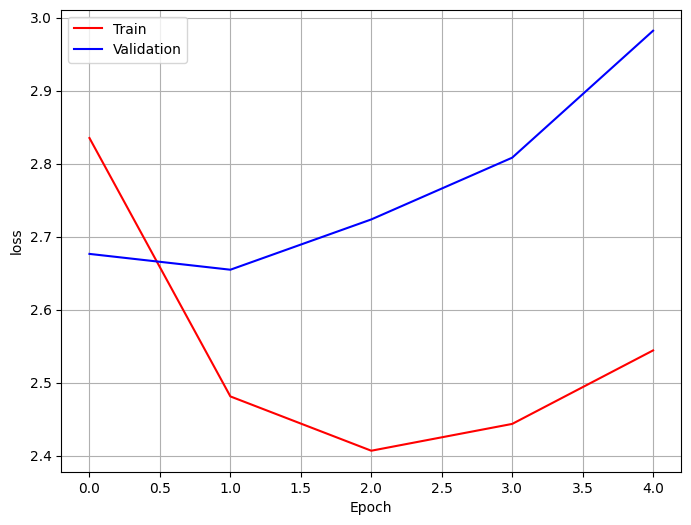

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(range(epoch_counter), loss_train_hist, 'r-', label='Train')
plt.plot(range(epoch_counter), loss_valid_hist, 'b-', label='Validation')

plt.xlabel('Epoch')
plt.ylabel('loss')
plt.grid(True)
plt.legend()

# 🔴 **Caption**

🔰The goal is to write a `caption` function and use a desired image to evaluate the model

## 🟠 Load the Best Saved Model

Load the saved model checkpoint from disk and switch the model to evaluation mode before caption generation.

In [ ]:
model_path = 'model.pt'
model = torch.load(model_path, weights_only=False)
model.eval()
print("Model loaded successfully!")

Model loaded successfully!


### 🟠 Define the Caption-Generation Wrapper

Provide a small wrapper around the model's `generate` method for producing a caption from an input image.

In [ ]:
def generate(image, model, vocab, max_seq_len, device):

    return model.generate(image, max_length=max_seq_len, device=device)

### 🟠 Prepare the Test Dataset for Caption Generation

Create the test dataset in evaluation mode so that both the transformed image and its original image/caption information are available for qualitative inspection.

In [ ]:
test_set_generate = Flickr8k(root, ann_file, split_file('test'), False, eval_transform, caption_transform)

### 🟠 Generate a Caption for a Test Image

Select a test image, generate a caption with the trained model, and display the generated caption alongside the reference caption and original image.

Target:  A little tan dog with large ears running through the grass .
Model: Virtle is walking through the grass . It is a small dog . It is carrying a red


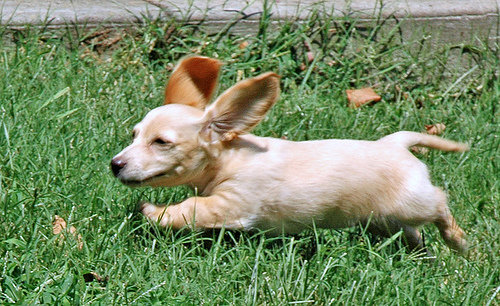

In [ ]:
idx = torch.randint(0, len(test_set_generate), (1,)).item()
image, image_raw, target = test_set_generate[30]

# Passed None instead of caption_transform.vocab since generate() doesn't use it
caption = generate(image.unsqueeze(0), model, None, 20, device)

print('Target: ', target)
print('Model:', caption)
image_raw

# 🔴 **Test**

🔰 Test model using data from the test set

## 🟠 Define BLEU Evaluation

Implement BLEU-score calculation by generating captions for test images and comparing the generated text with the corresponding reference captions.

In [ ]:
def calculate_bleu(model, dataloader, tokenizer, vocab, n_gram, device, max_seq_len=20):
    bleu = BLEUScore(n_gram=n_gram)
    for images, _, captions in dataloader:
        images = images.to(device)

        # Generate caption using the model
        generated_caption = generate(images[[0], ...], model, vocab, max_seq_len, device)

        candidates = [generated_caption]
        references = [captions]

        bleu.update(candidates, references)

    return bleu.compute()

### 🟠 Create the Test DataLoader for BLEU Evaluation

Build the test DataLoader used to provide images and reference captions to the BLEU evaluation functions.

In [ ]:
test_set_generate = Flickr8k(root, ann_file, split_file('test'), False, eval_transform, caption_transform)
test_loader = DataLoader(test_set_generate, batch_size=5, collate_fn=collate_fn)

### 🟠 Inspect Reference Captions

Display the captions from one test batch to verify the reference format used during BLEU evaluation.

In [ ]:
_, _, captions = next(iter(test_loader))
captions

('A blond woman in a blue shirt appears to wait for a ride .',
 'A blond woman is on the street hailing a taxi .',
 'A woman is signaling is to traffic , as seen from behind .',
 'A woman with blonde hair wearing a blue tube top is waving on the side of the street .',
 'The woman in the blue dress is holding out her arm at oncoming traffic .')

### 🟠 Compute BLEU Scores Safely

Calculate BLEU-1 through BLEU-4 while skipping generated captions that are too short to form the requested n-gram, preventing errors during metric computation.

In [ ]:
def calculate_bleu_safe(model, dataloader, tokenizer, vocab, n_gram, device, max_seq_len=20):
    bleu = BLEUScore(n_gram=n_gram)
    for images, _, captions in dataloader:
        images = images.to(device)
        generated_caption = generate(images[[0], ...], model, vocab, max_seq_len, device)

        # Split into words to check token length
        cand_words = generated_caption.strip().split()
        # If candidate is too short to construct an n-gram, skip this batch to avoid Torcheval crash
        if len(cand_words) < n_gram:
            continue

        candidates = [generated_caption]
        references = [captions]
        bleu.update(candidates, references)
    return bleu.compute()

bleu_1 = calculate_bleu_safe(model, test_loader, caption_transform.tokenizer, None, 1, device)
bleu_2 = calculate_bleu_safe(model, test_loader, caption_transform.tokenizer, None, 2, device)
bleu_3 = calculate_bleu_safe(model, test_loader, caption_transform.tokenizer, None, 3, device)
bleu_4 = calculate_bleu_safe(model, test_loader, caption_transform.tokenizer, None, 4, device)

### 🟠 Report BLEU Results

Print the final BLEU-1, BLEU-2, BLEU-3, and BLEU-4 scores produced on the test set.

In [ ]:
print(f'BLEU 1: {bleu_1}\nBLEU 2: {bleu_2}\nBLEU 3: {bleu_3}\nBLEU 4: {bleu_4}')

BLEU 1: 0.4047178797557012
BLEU 2: 0.24502489019124823
BLEU 3: 0.1466188240335454
BLEU 4: 0.08803687629772183
